# Capítulo 5 · Regresión logística

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/riosinda/ml-course/blob/main/notebooks/lectures/chapter_05/04_regresion_logistica.ipynb)

**Aprendizaje supervisado · Parte 4**

Vamos a predecir la especie de una flor de **Iris** a partir de sus medidas, como en la lectura de árboles. Aunque se llame regresión, `LogisticRegression` sirve para **clasificar**.

El flujo es: **cargar datos → separar → escalar → entrenar → predecir → evaluar**.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
raiz = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "pyproject.toml").exists()), Path.cwd())
DATA_DIR = raiz / "data"

## 1. Datos y exploración

Usaremos las cuatro medidas de cada flor para predecir su especie: **setosa, versicolor o virginica**.

Si falta `data/iris.csv`, ejecuta `uv run python scripts/download_data.py` desde la raíz del repositorio.

In [2]:
df = pd.read_csv(DATA_DIR / "iris.csv")
df.columns = ["largo_sepalo", "ancho_sepalo", "largo_petalo", "ancho_petalo", "especie"]
df["especie"] = df["especie"].map({0: "setosa", 1: "versicolor", 2: "virginica"})
df.head()

,largo_sepalo,ancho_sepalo,largo_petalo,ancho_petalo,especie
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
print("Filas y columnas:", df.shape)
print("Valores nulos:", df.isna().sum().sum())
print("Flores por especie:\n", df["especie"].value_counts())

Filas y columnas: (150, 5)
Valores nulos: 0
Flores por especie:
 especie
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


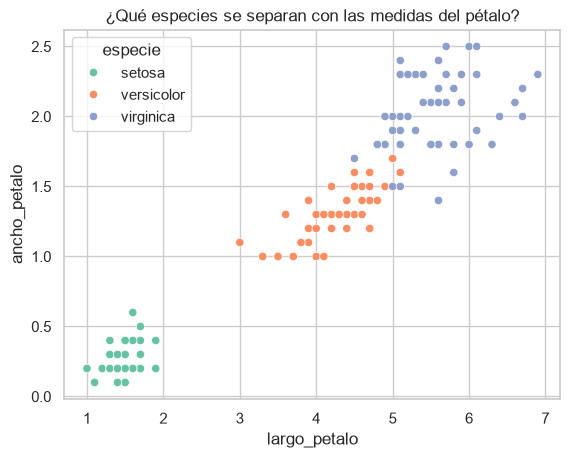

In [4]:
sns.scatterplot(data=df, x="largo_petalo", y="ancho_petalo", hue="especie", palette="Set2")
plt.title("¿Qué especies se separan con las medidas del pétalo?")
plt.show()

## 2. Separar train y test

Quitamos duplicados antes de separar para evitar que una misma fila aparezca en ambos conjuntos. Reservamos el **20 % para la evaluación final**; `stratify` conserva la proporción de especies.

In [5]:
df = df.drop_duplicates().reset_index(drop=True)
X = df.drop(columns="especie")
y = df["especie"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (119, 4) | Test: (30, 4)


## 3. Entrenar el modelo

`StandardScaler` pone las medidas en una escala comparable. El `Pipeline` une ese paso con el clasificador: al llamar a `fit`, ambos aprenden **solo con train**.

In [6]:
modelo = Pipeline([
    ("escalador", StandardScaler()),
    ("logistica", LogisticRegression()),
])
modelo.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('escalador', ...), ('logistica', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['setosa','versicolor','virginica']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['largo_sepalo','ancho_sepalo','largo_petalo','ancho_petalo']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


## 4. Predecir y evaluar

`predict` devuelve la especie predicha. La **accuracy** es la proporción de aciertos en test; la matriz de confusión muestra qué especies se confunden.

El reporte de clasificación muestra **precision** (cuántas predicciones de una especie son correctas), **recall** (cuántas flores de esa especie detecta), **F1-score** (combina ambas) y **support** (cuántas flores reales hay de cada especie).


Accuracy en test: 93.3%
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



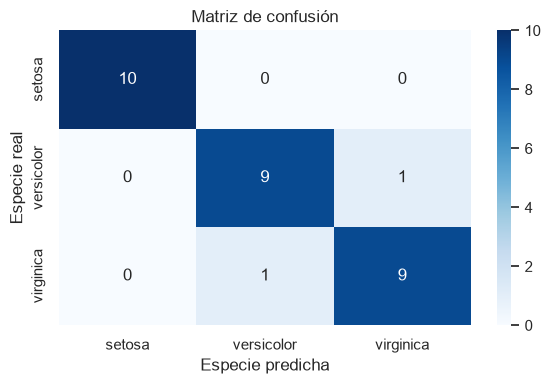

In [7]:
predicciones = modelo.predict(X_test)
print(f"Accuracy en test: {accuracy_score(y_test, predicciones):.1%}")
print(classification_report(y_test, predicciones, zero_division=0))

matriz = confusion_matrix(y_test, predicciones, labels=modelo.classes_)

plt.figure(figsize=(6, 4))
sns.heatmap(
    matriz, annot=True, fmt="d", cmap="Blues",
    xticklabels=modelo.classes_, yticklabels=modelo.classes_,
)
plt.xlabel("Especie predicha")
plt.ylabel("Especie real")
plt.title("Matriz de confusión")
plt.tight_layout()
plt.show()

## 5. Ver probabilidades

`predict_proba` devuelve una probabilidad por especie. Las columnas siguen el orden de `classes_`; la especie con mayor probabilidad es la predicción.

In [8]:
flores = X_test.head()
pd.DataFrame(
    modelo.predict_proba(flores), columns=modelo.classes_, index=flores.index
).round(3)

,setosa,versicolor,virginica
69,0.025,0.945,0.030
66,0.049,0.733,0.218
141,0.000,0.056,0.943
7,0.976,0.024,0.000
146,0.001,0.148,0.852
